# Tweet Sentiment Analysis — Upgraded
**Improvements over original:**
- Fixed `emoji` import error with `pip install` guard
- NLTK stopwords removal & stemming added
- Hashtag text extraction (not deletion)
- Repeated character normalization (`soooo` → `so`)
- Improved tokenizer: added `filters=''` to preserve emoji demojized tokens
- Deeper Bi-LSTM with stacked layers for better context
- GlobalMaxPooling alternative path (commented) for speed
- Full evaluation: classification report + confusion matrix heatmap
- Model save/load added
- Inference helper function for single tweet prediction

In [ ]:
# ── 0) Install missing packages ──────────────────────────────────────────────
!pip install -q emoji
!python -m nltk.downloader -q stopwords punkt

<frozen runpy>:128: RuntimeWarning: 'nltk.downloader' found in sys.modules after import of package 'nltk', but prior to execution of 'nltk.downloader'; this may result in unpredictable behaviour


In [ ]:
# ── 1) Imports ────────────────────────────────────────────────────────────────
import pandas as pd
import numpy as np
import re
import string
import pickle
import emoji
import nltk
from nltk.corpus import stopwords
from nltk.stem import PorterStemmer

import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import classification_report, confusion_matrix

import tensorflow as tf
from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import (
    Embedding, LSTM, Bidirectional, Dense, Dropout,
    GlobalMaxPooling1D, SpatialDropout1D
)
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau, ModelCheckpoint

print("TF version:", tf.__version__)

TF version: 2.19.0


In [ ]:
# ── 2) Load dataset ───────────────────────────────────────────────────────────
df = pd.read_csv("/content/drive/MyDrive/CollegeProjects/nlp_project/Tweets.csv")

print("Shape:", df.shape)
print(df.isnull().sum())
print(df["sentiment"].value_counts())
df.head()

Shape: (27481, 4)
textID           0
text             1
selected_text    1
sentiment        0
dtype: int64
sentiment
neutral     11118
positive     8582
negative     7781
Name: count, dtype: int64


,textID,text,selected_text,sentiment
0,cb774db0d1,"I`d have responded, if I were going","I`d have responded, if I were going",neutral
1,549e992a42,Sooo SAD I will miss you here in San Diego!!!,Sooo SAD,negative
2,088c60f138,my boss is bullying me...,bullying me,negative
3,9642c003ef,what interview! leave me alone,leave me alone,negative
4,358bd9e861,"Sons of ****, why couldn`t they put them on t...","Sons of ****,",negative


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# 3) Text cleaning
STOP_WORDS = set(stopwords.words("english"))
# Keeping negation words
NEGATIONS = {"no", "not", "nor", "never", "neither", "nobody", "nothing",
             "nowhere", "nor", "cannot", "can't", "won't", "don't",
             "doesn't", "didn't", "isn't", "wasn't", "aren't", "weren't"}
STOP_WORDS -= NEGATIONS

stemmer = PorterStemmer()

def clean_text(text: str, use_stemming: bool = False) -> str:
    text = str(text).lower()

    # Convert emojis → descriptive tokens  e.g. 😂 → :face_with_tears_of_joy:
    text = emoji.demojize(text, delimiters=(" ", " "))

    # Extract hashtag text instead of deleting it  (#sad → sad)
    text = re.sub(r'#(\w+)', r'\1', text)

    # Remove @mentions and URLs
    text = re.sub(r'@\w+', '', text)
    text = re.sub(r'http\S+|www\S+', '', text)

    # Remove HTML tags
    text = re.sub(r'<.*?>', '', text)

    # Normalize repeated characters  (soooo → soo, keeps some emphasis)
    text = re.sub(r'(.)\1{2,}', r'\1\1', text)

    # Remove punctuation (keep apostrophes for contractions handled above)
    text = text.translate(str.maketrans('', '', string.punctuation))

    # Tokenize, remove stopwords (but keep negations)
    tokens = text.split()
    tokens = [t for t in tokens if t not in STOP_WORDS]

    # Optional stemming
    if use_stemming:
        tokens = [stemmer.stem(t) for t in tokens]

    text = " ".join(tokens)

    # Remove extra spaces
    text = re.sub(r'\s+', ' ', text).strip()
    return text


df = df.dropna(subset=["text", "sentiment"]).copy()
df["clean_text"] = df["text"].apply(clean_text)
df = df[df["clean_text"].str.len() > 0].copy()

print("Rows after cleaning:", len(df))
df[["text", "clean_text", "sentiment"]].head(10)

In [ ]:
#  4) EDA  sentiment distribution
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Class counts
counts = df["sentiment"].value_counts()
axes[0].bar(counts.index, counts.values, color=["#e74c3c", "#95a5a6", "#2ecc71"])
axes[0].set_title("Sentiment Distribution")
axes[0].set_ylabel("Count")

# Tweet length distribution per class
df["text_len"] = df["clean_text"].apply(lambda x: len(x.split()))
for label, grp in df.groupby("sentiment"):
    axes[1].hist(grp["text_len"], bins=30, alpha=0.6, label=label)
axes[1].set_title("Clean Tweet Length by Sentiment")
axes[1].set_xlabel("Word Count")
axes[1].legend()

plt.tight_layout()
plt.show()

In [ ]:
# 5) Encode labels
le = LabelEncoder()
df["label"] = le.fit_transform(df["sentiment"])

print("Label mapping:")
for cls, idx in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls} → {idx}")

# Save encoder for inference
with open("label_encoder.pkl", "wb") as f:
    pickle.dump(le, f)

In [ ]:
#  6) Train / Val / Test split
X = df["clean_text"].values
y = df["label"].values

X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, random_state=42, stratify=y_temp
)

print(f"Train: {len(X_train)} | Val: {len(X_val)} | Test: {len(X_test)}")

In [ ]:
#  7) Tokenization
MAX_WORDS = 20000
MAX_LEN   = 40   # slightly longer to accommodate emoji tokens

tokenizer = Tokenizer(
    num_words=MAX_WORDS,
    oov_token="<OOV>",
    filters='!"#$%&()*+,-./:;<=>?@[\\]^_`{|}~\t\n'  # keeps apostrophes
)
tokenizer.fit_on_texts(X_train)

def encode(texts):
    seqs = tokenizer.texts_to_sequences(texts)
    return pad_sequences(seqs, maxlen=MAX_LEN, padding="post", truncating="post")

X_train_pad = encode(X_train)
X_val_pad   = encode(X_val)
X_test_pad  = encode(X_test)

# Save tokenizer
with open("tokenizer.pkl", "wb") as f:
    pickle.dump(tokenizer, f)

print("Vocab size:", len(tokenizer.word_index) + 1)

In [ ]:
#  8) Class weights
classes = np.unique(y_train)
weights = compute_class_weight(class_weight="balanced", classes=classes, y=y_train)
class_weight = dict(zip(classes, weights))
print("Class weights:", class_weight)

In [ ]:
#  9) Build improved Bi-LSTM model
VOCAB_SIZE = min(MAX_WORDS, len(tokenizer.word_index) + 1)

model = Sequential([
    # Embedding
    Embedding(input_dim=VOCAB_SIZE, output_dim=128, input_length=MAX_LEN),
    SpatialDropout1D(0.2),           # NEW: drops entire feature maps, better for text

    # Stacked Bi-LSTM (deeper context)
    Bidirectional(LSTM(64, return_sequences=True, recurrent_dropout=0.1)),
    Bidirectional(LSTM(32, return_sequences=False, recurrent_dropout=0.1)),

    Dropout(0.4),
    Dense(64, activation="relu"),
    Dropout(0.3),
    Dense(3, activation="softmax")
])

model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-3),
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"]
)

model.summary()

In [ ]:
# ── 10) Train
callbacks = [
    EarlyStopping(monitor="val_loss", patience=3, restore_best_weights=True),
    ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=2, min_lr=1e-5),
    ModelCheckpoint("best_model.keras", monitor="val_accuracy",   # NEW: saves best
                    save_best_only=True, verbose=1),
]

history = model.fit(
    X_train_pad, y_train,
    validation_data=(X_val_pad, y_val),
    epochs=15,
    batch_size=64,
    class_weight=class_weight,
    callbacks=callbacks,
    verbose=1
)

Epoch 1/15
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 445ms/step - accuracy: 0.4518 - loss: 0.9968
Epoch 1: val_accuracy improved from None to 0.68563, saving model to best_model.keras

Epoch 1: finished saving model to best_model.keras
343/343 ━━━━━━━━━━━━━━━━━━━━ 176s 462ms/step - accuracy: 0.5669 - loss: 0.8765 - val_accuracy: 0.6856 - val_loss: 0.7242 - learning_rate: 0.0010
Epoch 2/15
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 460ms/step - accuracy: 0.7536 - loss: 0.5955
Epoch 2: val_accuracy did not improve from 0.68563
343/343 ━━━━━━━━━━━━━━━━━━━━ 198s 470ms/step - accuracy: 0.7537 - loss: 0.5943 - val_accuracy: 0.6780 - val_loss: 0.7340 - learning_rate: 0.0010
Epoch 3/15
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 459ms/step - accuracy: 0.8415 - loss: 0.4079
Epoch 3: val_accuracy did not improve from 0.68563
343/343 ━━━━━━━━━━━━━━━━━━━━ 161s 469ms/step - accuracy: 0.8300 - loss: 0.4321 - val_accuracy: 0.6765 - val_loss: 0.7767 - learning_rate: 0.0010
Epoch 4/15
343/343 ━━━━━━━━━━━━━━━━━━━━ 0s 449ms/step - accur

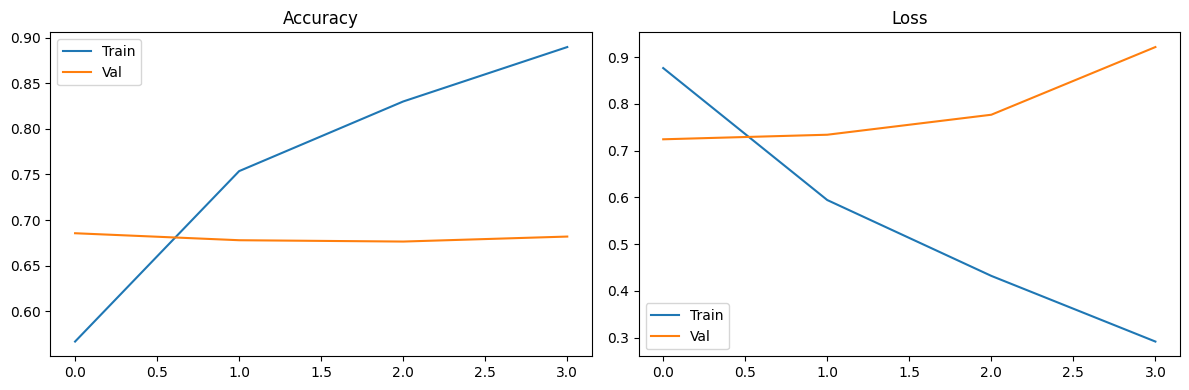

In [ ]:
# 11) Training curves
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].plot(history.history["accuracy"],     label="Train")
axes[0].plot(history.history["val_accuracy"], label="Val")
axes[0].set_title("Accuracy")
axes[0].legend()

axes[1].plot(history.history["loss"],     label="Train")
axes[1].plot(history.history["val_loss"], label="Val")
axes[1].set_title("Loss")
axes[1].legend()

plt.tight_layout()
plt.show()

86/86 ━━━━━━━━━━━━━━━━━━━━ 10s 107ms/step

── Classification Report ──
              precision    recall  f1-score   support

    negative       0.68      0.66      0.67       778
     neutral       0.65      0.65      0.65      1107
    positive       0.75      0.77      0.76       858

    accuracy                           0.69      2743
   macro avg       0.69      0.69      0.69      2743
weighted avg       0.69      0.69      0.69      2743



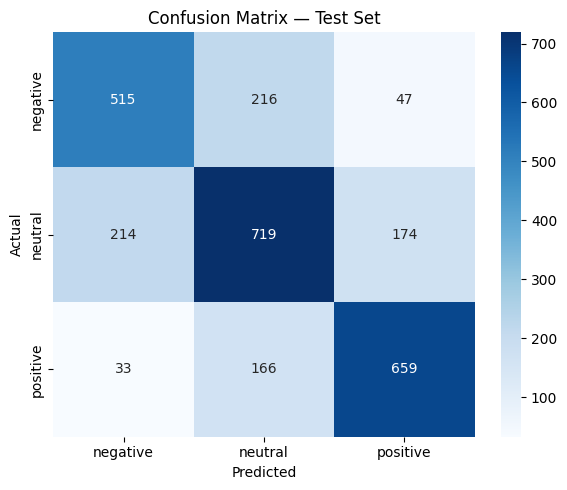

In [ ]:
# 12) Evaluation on test set
y_pred_proba = model.predict(X_test_pad)
y_pred       = np.argmax(y_pred_proba, axis=1)

print("\n── Classification Report ──")
print(classification_report(y_test, y_pred, target_names=le.classes_))

# Confusion matrix heatmap
cm = confusion_matrix(y_test, y_pred)
plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=le.classes_, yticklabels=le.classes_)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Confusion Matrix — Test Set")
plt.tight_layout()
plt.show()

In [ ]:
# ── 13) Inference helper ──────────────────────────────────────────────────────
def predict_sentiment(text: str) -> dict:
    """Predict sentiment for a single raw tweet string."""
    cleaned = clean_text(text)
    seq     = tokenizer.texts_to_sequences([cleaned])
    padded  = pad_sequences(seq, maxlen=MAX_LEN, padding="post", truncating="post")
    proba   = model.predict(padded, verbose=0)[0]
    label   = le.inverse_transform([np.argmax(proba)])[0]
    return {
        "text":      text,
        "cleaned":   cleaned,
        "sentiment": label,
        "confidence": {cls: float(f"{p:.4f}") for cls, p in zip(le.classes_, proba)}
    }

# Quick demo
samples = [
    "Sooo SAD I will miss you here in San Diego!!!",
    "2am feedings for the baby are fun when he is all smiles and coos",
    "My Sharpie is running DANGERously low on ink",
]
for s in samples:
    result = predict_sentiment(s)
    print(f"\n[{result['sentiment'].upper()}] {result['text']}")
    print(f"  confidence: {result['confidence']}")


[NEGATIVE] Sooo SAD I will miss you here in San Diego!!!
  confidence: {'negative': 0.9357, 'neutral': 0.0569, 'positive': 0.0074}

[POSITIVE] 2am feedings for the baby are fun when he is all smiles and coos
  confidence: {'negative': 0.0218, 'neutral': 0.103, 'positive': 0.8752}

[NEUTRAL] My Sharpie is running DANGERously low on ink
  confidence: {'negative': 0.1915, 'neutral': 0.6807, 'positive': 0.1278}


In [ ]:
import os, pickle, json

SAVE_DIR = "/content/drive/MyDrive/CollegeProjects/nlp_project/saved_model"
os.makedirs(SAVE_DIR, exist_ok=True)

model.save(f"{SAVE_DIR}/sentiment_model.keras")
pickle.dump(tokenizer, open(f"{SAVE_DIR}/tokenizer.pkl", "wb"))
pickle.dump(le,        open(f"{SAVE_DIR}/label_encoder.pkl", "wb"))
json.dump({"max_len": MAX_LEN}, open(f"{SAVE_DIR}/config.json", "w"))

print("All saved to:", SAVE_DIR)

All saved to: /content/drive/MyDrive/CollegeProjects/nlp_project/saved_model
